# 实践实验：应用机器学习的建议
在本实验中，你将探索评估和改进你机器学习模型的技术。

# 大纲
- [ 1 - 软件包 ](#1)
- [ 2 - 评估一个学习算法（多项式回归）](#2)
  - [ 2.1 划分你的数据集](#2.1)
  - [ 2.2 用于模型评估的误差计算，线性回归](#2.2)
    - [ 练习 1](#ex01)
  - [ 2.3 比较在训练数据和测试数据上的性能](#2.3)
- [ 3 - 偏差与方差<img align="Right" src="./images/C2_W3_BiasVarianceDegree.png"  style=" width:500px; padding: 10px 20px ; "> ](#3)
  - [ 3.1 绘制训练、交叉验证、测试](#3.1)
  - [ 3.2 找到最优的次数](#3.2)
  - [ 3.3 调优正则化。](#3.3)
  - [ 3.4 获取更多数据：增大训练集规模 (m)](#3.4)
- [ 4 - 评估一个学习算法（神经网络）](#4)
  - [ 4.1 数据集](#4.1)
  - [ 4.2 通过计算分类误差来评估分类模型](#4.2)
    - [ 练习 2](#ex02)
- [ 5 - 模型复杂度](#5)
  - [ 练习 3](#ex03)
  - [ 5.1 简单模型](#5.1)
    - [ 练习 4](#ex04)
- [ 6 - 正则化](#6)
  - [ 练习 5](#ex05)
- [ 7 - 迭代以找到最优的正则化值](#7)
  - [ 7.1 测试](#7.1)


_**注意：** 为防止自动评分器报错，你不得编辑或删除本笔记本中不参与评分的单元格。也请不要添加任何新单元格。
**一旦你通过了本次作业** 并想试验任何不参与评分的代码，你可以按照本笔记本底部的说明操作。_

<a name="1"></a>
## 1 - 软件包

首先，让我们运行下面的单元格，导入本次作业中你需要的所有软件包。
- [numpy](https://numpy.org/) 是用 Python 进行科学计算的基础软件包。
- [matplotlib](http://matplotlib.org) 是 Python 中流行的绘图库。
- [scikitlearn](https://scikit-learn.org/stable/) 是一个用于数据挖掘的基础库
- [tensorflow](https://www.tensorflow.org/) 是一个流行的机器学习平台。

In [2]:
import numpy as np
%matplotlib widget
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.activations import relu,linear
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam

import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)

from public_tests_a1 import * 

tf.keras.backend.set_floatx('float64')
from assigment_utils import *

tf.autograph.set_verbosity(0)

<a name="2"></a>
## 2 - 评估一个学习算法（多项式回归）

<img align="Right" src="./images/C2_W3_TrainingVsNew.png"  style=" width:350px; padding: 10px 20px ; "> 假设你已经创建了一个机器学习模型，并且发现它非常*拟合*你的训练数据。你就完成了吗？还不完全是。创建模型的目标是能够预测<span style="color:blue">*新*</span>样本的值。

在部署你的模型之前，你如何在*新*数据上测试它的性能？
答案有两部分：
* 把你的原始数据集划分为"训练"集和"测试"集。
    * 用训练数据来拟合模型的参数
    * 用测试数据来在*新*数据上评估模型
* 开发一个误差函数来评估你的模型。

<a name="2.1"></a>
### 2.1 划分你的数据集
课程建议保留你数据集的 20-40% 用于测试。让我们用一个 `sklearn` 函数 [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) 来执行这个划分。运行下面的单元格后，请再核对一下形状。

In [3]:
# Generate some data
X,y,x_ideal,y_ideal = gen_data(18, 2, 0.7)
print("X.shape", X.shape, "y.shape", y.shape)

#split the data using sklearn routine 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.33, random_state=1)
print("X_train.shape", X_train.shape, "y_train.shape", y_train.shape)
print("X_test.shape", X_test.shape, "y_test.shape", y_test.shape)

X.shape (18,) y.shape (18,)
X_train.shape (12,) y_train.shape (12,)
X_test.shape (6,) y_test.shape (6,)


#### 2.1.1 绘制训练集、测试集
在下面你可以看到，将作为训练一部分的数据点（红色）与模型未在其上训练的数据点（测试）混杂在一起。这个特定的数据集是一个加了噪声的二次函数。图中展示了"理想"曲线以供参考。

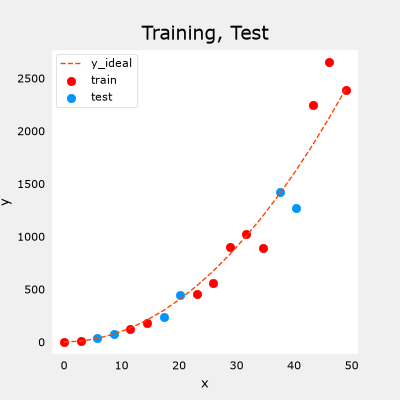

In [4]:
fig, ax = plt.subplots(1,1,figsize=(4,4))
ax.plot(x_ideal, y_ideal, "--", color = "orangered", label="y_ideal", lw=1)
ax.set_title("Training, Test",fontsize = 14)
ax.set_xlabel("x")
ax.set_ylabel("y")

ax.scatter(X_train, y_train, color = "red",           label="train")
ax.scatter(X_test, y_test,   color = dlc["dlblue"],   label="test")
ax.legend(loc='upper left')
plt.show()

<a name="2.2"></a>
### 2.2 用于模型评估的误差计算，线性回归
当*评估*一个线性回归模型时，你对预测值与目标值之间的平方误差差值求平均。

$$ J_\text{test}(\mathbf{w},b) = 
            \frac{1}{2m_\text{test}}\sum_{i=0}^{m_\text{test}-1} ( f_{\mathbf{w},b}(\mathbf{x}^{(i)}_\text{test}) - y^{(i)}_\text{test} )^2 
            \tag{1}
$$

<a name="ex01"></a>
### 练习 1

在下面，创建一个函数来评估线性回归模型在一个数据集上的误差。

In [5]:
# UNQ_C1
# GRADED CELL: eval_mse
def eval_mse(y, yhat):
    """ 
    Calculate the mean squared error on a data set.
    Args:
      y    : (ndarray  Shape (m,) or (m,1))  target value of each example
      yhat : (ndarray  Shape (m,) or (m,1))  predicted value of each example
    Returns:
      err: (scalar)             
    """
    m = len(y)
    err = 0.0
    for i in range(m):
    ### START CODE HERE ### 
       err+=(y[i]-yhat[i])**2
        
    err/=(2*m)
    ### END CODE HERE ### 
    
    return(err)

In [6]:
y_hat = np.array([2.4, 4.2])
y_tmp = np.array([2.3, 4.1])
eval_mse(y_hat, y_tmp)

# BEGIN UNIT TEST
test_eval_mse(eval_mse)   
# END UNIT TEST

 All tests passed.


<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>

    
```python
def eval_mse(y, yhat):
    """ 
    Calculate the mean squared error on a data set.
    Args:
      y    : (ndarray  Shape (m,) or (m,1))  target value of each example
      yhat : (ndarray  Shape (m,) or (m,1))  predicted value of each example
    Returns:
      err: (scalar)             
    """
    m = len(y)
    err = 0.0
    for i in range(m):
        err_i  = ( (yhat[i] - y[i])**2 ) 
        err   += err_i                                                                
    err = err / (2*m)                    
    return(err)
``` 

<a name="2.3"></a>
### 2.3 比较在训练数据和测试数据上的性能
让我们构建一个高次多项式模型来最小化训练误差。这将使用来自 `sklearn` 的 linear_regression 函数。如果你想了解细节，这些代码在导入的工具文件中。下面的步骤是：
* 创建并拟合模型。（'fit' 是训练或运行梯度下降的另一种说法）。
* 计算在训练数据上的误差。
* 计算在测试数据上的误差。

In [7]:
# create a model in sklearn, train on training data
degree = 10
lmodel = lin_model(degree)
lmodel.fit(X_train, y_train)

# predict on training data, find training error
yhat = lmodel.predict(X_train)
err_train = lmodel.mse(y_train, yhat)

# predict on test data, find error
yhat = lmodel.predict(X_test)
err_test = lmodel.mse(y_test, yhat)

在训练集上计算出的误差明显小于在测试集上的误差。

In [8]:
print(f"training err {err_train:0.2f}, test err {err_test:0.2f}")

training err 2086.18, test err 21384.05


下面的图展示了为什么会这样。模型非常拟合训练数据。为了做到这一点，它创建了一个复杂的函数。测试数据不是训练的一部分，模型在这些数据上的预测做得很差。
这个模型将被描述为：1）过拟合，2）具有高方差，3）"泛化"能力差。

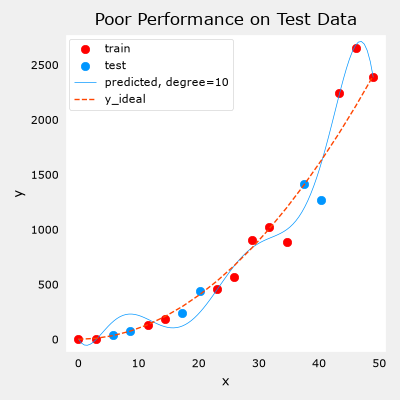

In [9]:
# plot predictions over data range 
x = np.linspace(0,int(X.max()),100)  # predict values for plot
y_pred = lmodel.predict(x).reshape(-1,1)

plt_train_test(X_train, y_train, X_test, y_test, x, y_pred, x_ideal, y_ideal, degree)

测试集误差表明这个模型在新数据上不会表现良好。如果你用测试误差来指导模型的改进，那么模型会在测试数据上表现良好……但测试数据本意是代表*新*数据。
你还需要另一组数据来测试在新数据上的性能。

课程中提出的建议是把数据分成三组。下表中所示的训练、交叉验证和测试集的分布是一个典型的分布，但可以根据可用数据量而变化。

| data             | % of total | Description |
|------------------|:----------:|:---------|
| training         | 60         | 用于在训练或拟合中调优模型参数 $w$ 和 $b$ 的数据 |
| cross-validation | 20         | 用于调优其他模型参数的数据，如多项式的次数、正则化或神经网络的架构。|
| test             | 20         | 用于在调优之后测试模型、以衡量其在新数据上性能的数据 |


让我们在下面生成三个数据集。我们将再次使用来自 `sklearn` 的 `train_test_split`，但会调用它两次以得到三个划分：

In [10]:
# Generate  data
X,y, x_ideal,y_ideal = gen_data(40, 5, 0.7)
print("X.shape", X.shape, "y.shape", y.shape)

#split the data using sklearn routine 
X_train, X_, y_train, y_ = train_test_split(X,y,test_size=0.40, random_state=1)
X_cv, X_test, y_cv, y_test = train_test_split(X_,y_,test_size=0.50, random_state=1)
print("X_train.shape", X_train.shape, "y_train.shape", y_train.shape)
print("X_cv.shape", X_cv.shape, "y_cv.shape", y_cv.shape)
print("X_test.shape", X_test.shape, "y_test.shape", y_test.shape)

X.shape (40,) y.shape (40,)
X_train.shape (24,) y_train.shape (24,)
X_cv.shape (8,) y_cv.shape (8,)
X_test.shape (8,) y_test.shape (8,)


<a name="3"></a>
## 3 - 偏差与方差<img align="Right" src="./images/C2_W3_BiasVarianceDegree.png"  style=" width:500px; padding: 10px 20px ; "> 
在上面，很明显多项式模型的次数太高了。你如何选择一个好的值？事实证明，如图中所示，训练和交叉验证的性能可以提供指导。通过尝试一系列次数值，可以评估训练和交叉验证的性能。当次数变得太大时，交叉验证性能会相对于训练性能开始变差。让我们在我们的例子上试试这个。

<a name="3.1"></a>
### 3.1 绘制训练、交叉验证、测试
在下面你可以看到，将作为训练一部分的数据点（红色）与模型未在其上训练的数据点（测试和 cv）混杂在一起。

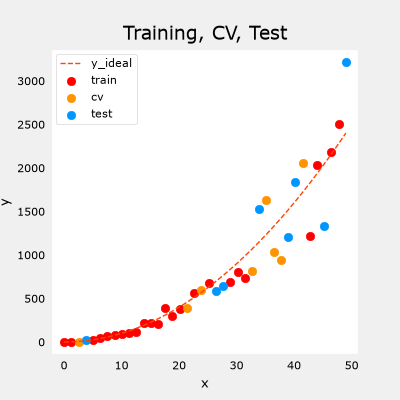

In [11]:
fig, ax = plt.subplots(1,1,figsize=(4,4))
ax.plot(x_ideal, y_ideal, "--", color = "orangered", label="y_ideal", lw=1)
ax.set_title("Training, CV, Test",fontsize = 14)
ax.set_xlabel("x")
ax.set_ylabel("y")

ax.scatter(X_train, y_train, color = "red",           label="train")
ax.scatter(X_cv, y_cv,       color = dlc["dlorange"], label="cv")
ax.scatter(X_test, y_test,   color = dlc["dlblue"],   label="test")
ax.legend(loc='upper left')
plt.show()

<a name="3.2"></a>
### 3.2 找到最优的次数
在之前的实验中，你发现你可以通过利用多项式来创建一个能够拟合复杂曲线的模型（见 Course1, Week2 特征工程与多项式回归实验）。此外，你已经证明通过增加多项式的*次数*，你可以*造成*过拟合。（见 Course 1, Week3, 过拟合实验）。让我们在这里利用这些知识来测试我们区分过拟合与欠拟合的能力。

让我们反复训练模型，每次迭代增加多项式的次数。这里，为了速度和简单起见，我们将使用 [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression) 线性回归模型。

In [12]:
max_degree = 9
err_train = np.zeros(max_degree)    
err_cv = np.zeros(max_degree)      
x = np.linspace(0,int(X.max()),100)  
y_pred = np.zeros((100,max_degree))  #columns are lines to plot

for degree in range(max_degree):
    lmodel = lin_model(degree+1)
    lmodel.fit(X_train, y_train)
    yhat = lmodel.predict(X_train)
    err_train[degree] = lmodel.mse(y_train, yhat)
    yhat = lmodel.predict(X_cv)
    err_cv[degree] = lmodel.mse(y_cv, yhat)
    y_pred[:,degree] = lmodel.predict(x)
    
optimal_degree = np.argmin(err_cv)+1

<font size="4">让我们来绘制结果：</font>

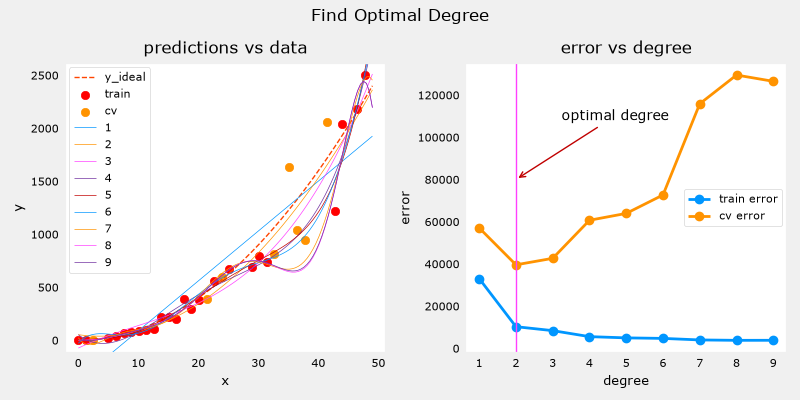

In [13]:
plt.close("all")
plt_optimal_degree(X_train, y_train, X_cv, y_cv, x, y_pred, x_ideal, y_ideal, 
                   err_train, err_cv, optimal_degree, max_degree)

上面的图证明，把数据分成两组——模型在其上训练的数据和模型未在其上训练的数据——可以用来判断模型是欠拟合还是过拟合。在我们的例子中，我们通过增加所用多项式的次数，创建了一系列从欠拟合到过拟合的模型。
- 在左图中，实线代表来自这些模型的预测。次数为 1 的多项式模型产生一条直线，它与很少的数据点相交，而最大次数的模型则紧贴每一个数据点。
- 在右边：
    - 在训练过的数据上的误差（蓝色）如预期般随模型复杂度增加而减小
    - 交叉验证数据的误差最初随模型开始符合数据而减小，但随后随模型开始在训练数据上过拟合而增大（未能*泛化*）。

值得注意的是，这些例子中的曲线并不像人们为课程所画的那样平滑。很明显，分配给每一组的具体数据点会显著改变你的结果。重要的是总体趋势。

<a name="3.3"></a>
### 3.3 调优正则化。
在之前的实验中，你利用*正则化*来减少过拟合。与次数类似，可以用同样的方法来调优正则化参数 lambda（$\lambda$）。

让我们从一个高次多项式开始并改变正则化参数来演示这一点。

In [14]:
lambda_range = np.array([0.0, 1e-6, 1e-5, 1e-4,1e-3,1e-2, 1e-1,1,10,100])
num_steps = len(lambda_range)
degree = 10
err_train = np.zeros(num_steps)    
err_cv = np.zeros(num_steps)       
x = np.linspace(0,int(X.max()),100) 
y_pred = np.zeros((100,num_steps))  #columns are lines to plot

for i in range(num_steps):
    lambda_= lambda_range[i]
    lmodel = lin_model(degree, regularization=True, lambda_=lambda_)
    lmodel.fit(X_train, y_train)
    yhat = lmodel.predict(X_train)
    err_train[i] = lmodel.mse(y_train, yhat)
    yhat = lmodel.predict(X_cv)
    err_cv[i] = lmodel.mse(y_cv, yhat)
    y_pred[:,i] = lmodel.predict(x)
    
optimal_reg_idx = np.argmin(err_cv) 

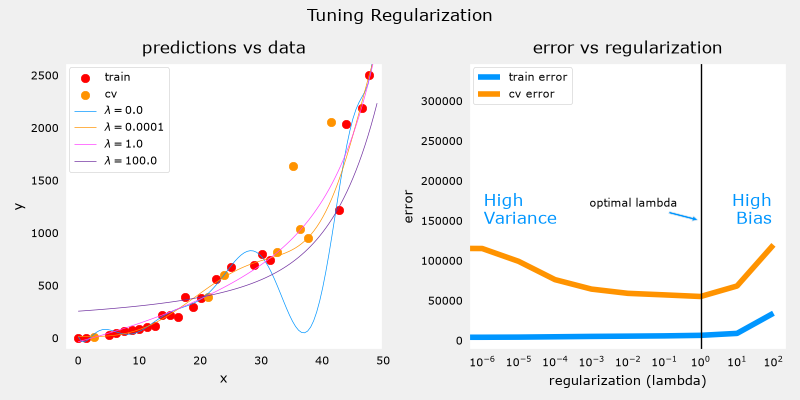

In [15]:
plt.close("all")
plt_tune_regularization(X_train, y_train, X_cv, y_cv, x, y_pred, err_train, err_cv, optimal_reg_idx, lambda_range)

在上面，这些图显示：随着正则化增加，模型从一个高方差（过拟合）模型移动到一个高偏差（欠拟合）模型。右图中的竖线显示了 lambda 的最优值。在这个例子中，多项式次数被设为 10。

<a name="3.4"></a>
### 3.4 获取更多数据：增大训练集规模 (m)
当一个模型过拟合（高方差）时，收集额外的数据可以改进性能。让我们在这里试试。

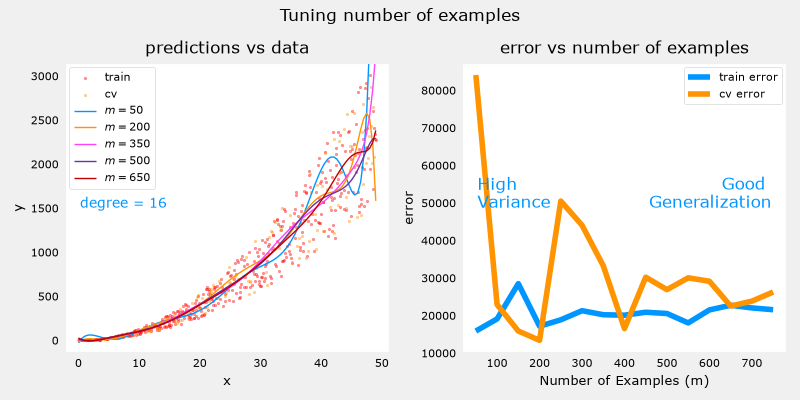

In [16]:
X_train, y_train, X_cv, y_cv, x, y_pred, err_train, err_cv, m_range,degree = tune_m()
plt_tune_m(X_train, y_train, X_cv, y_cv, x, y_pred, err_train, err_cv, m_range, degree)

上面的图显示：当一个模型具有高方差并过拟合时，添加更多样本能改进性能。请注意左图中的曲线。具有最高 $m$ 值的最终曲线是一条位于数据中心的光滑曲线。在右边，随着样本数量增加，训练集和交叉验证集的性能收敛到相近的值。请注意这些曲线并不像人们在课程中看到的那样平滑。这是可以预期的。趋势仍然清晰：更多数据改进泛化。

> 请注意，当模型具有高偏差（欠拟合）时，添加更多样本并不能改进性能。


<a name="4"></a>
## 4 - 评估一个学习算法（神经网络）
在上面，你调优了一个多项式回归模型的各个方面。这里，你将使用一个神经网络模型。让我们从创建一个分类数据集开始。

<a name="4.1"></a>
### 4.1 数据集
运行下面的单元格来生成一个数据集，并把它划分为训练、交叉验证（CV）和测试集。在这个例子中，为了强调，我们增大了交叉验证数据点的百分比。

In [17]:
# Generate and split data set
X, y, centers, classes, std = gen_blobs()

# split the data. Large CV population for demonstration
X_train, X_, y_train, y_ = train_test_split(X,y,test_size=0.50, random_state=1)
X_cv, X_test, y_cv, y_test = train_test_split(X_,y_,test_size=0.20, random_state=1)
print("X_train.shape:", X_train.shape, "X_cv.shape:", X_cv.shape, "X_test.shape:", X_test.shape)

X_train.shape: (400, 2) X_cv.shape: (320, 2) X_test.shape: (80, 2)


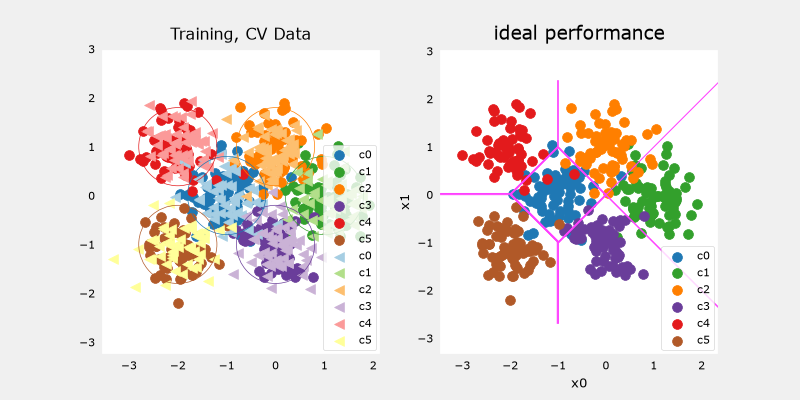

In [18]:
plt_train_eq_dist(X_train, y_train,classes, X_cv, y_cv, centers, std)

在上面，你可以在左边看到数据。有六个用颜色标识的簇。训练点（圆点）和交叉验证点（三角形）都被显示出来。有趣的是那些落在模糊位置的点，两个簇都可能认为它们是成员。你会期望一个神经网络模型怎么做？过拟合的例子会是什么？欠拟合呢？
在右边是一个"理想"模型的例子，或者说一个在知道数据来源的情况下人们可能会创建的模型。这些线代表"等距离"边界，即中心点之间的距离相等。值得注意的是，这个模型会"误分类"大约 8% 的整个数据集。

<a name="4.2"></a>
### 4.2 通过计算分类误差来评估分类模型
这里用于分类模型的评估函数就是错误预测所占的比例：
$$ J_{cv} =\frac{1}{m}\sum_{i=0}^{m-1} 
\begin{cases}
    1, & \text{if $\hat{y}^{(i)} \neq y^{(i)}$}\\
    0, & \text{otherwise}
\end{cases}
$$

<a name="ex02"></a>
### 练习 2

在下面，完成计算分类误差的程序。请注意，在本实验中，目标值是类别的索引，并且没有进行 [one-hot 编码](https://en.wikipedia.org/wiki/One-hot)。

In [19]:
# UNQ_C2
# GRADED CELL: eval_cat_err
def eval_cat_err(y, yhat):
    """ 
    Calculate the categorization error
    Args:
      y    : (ndarray  Shape (m,) or (m,1))  target value of each example
      yhat : (ndarray  Shape (m,) or (m,1))  predicted value of each example
    Returns:|
      cerr: (scalar)             
    """
    m = len(y)
    incorrect = 0
    for i in range(m):
    ### START CODE HERE ### 
       incorrect+=int(np.squeeze(y[i]!=yhat[i]))
            
    cerr=incorrect/m
    ### END CODE HERE ### 
    
    return(cerr)

In [20]:
y_hat = np.array([1, 2, 0])
y_tmp = np.array([1, 2, 3])
print(f"categorization error {np.squeeze(eval_cat_err(y_hat, y_tmp)):0.3f}, expected:0.333" )
y_hat = np.array([[1], [2], [0], [3]])
y_tmp = np.array([[1], [2], [1], [3]])
print(f"categorization error {np.squeeze(eval_cat_err(y_hat, y_tmp)):0.3f}, expected:0.250" )

# BEGIN UNIT TEST  
test_eval_cat_err(eval_cat_err)
# END UNIT TEST

categorization error 0.333, expected:0.333
categorization error 0.250, expected:0.250
 All tests passed.


<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
```python
def eval_cat_err(y, yhat):
    """ 
    Calculate the categorization error
    Args:
      y    : (ndarray  Shape (m,) or (m,1))  target value of each example
      yhat : (ndarray  Shape (m,) or (m,1))  predicted value of each example
    Returns:|
      cerr: (scalar)             
    """
    m = len(y)
    incorrect = 0
    for i in range(m):
        if yhat[i] != y[i]:    # @REPLACE
            incorrect += 1     # @REPLACE
    cerr = incorrect/m         # @REPLACE
    return(cerr)                                    
``` 

<a name="5"></a>
## 5 - 模型复杂度
在下面，你将构建两个模型。一个复杂模型和一个简单模型。你将评估这些模型，以判断它们是否可能过拟合或欠拟合。

###  5.1 复杂模型

<a name="ex03"></a>
### 练习 3
在下面，构建一个三层模型：
* 带 120 个单元的 Dense 层，relu 激活
* 带 40 个单元的 Dense 层，relu 激活
* 带 6 个单元、线性激活（不是 softmax）的 Dense 层
使用以下方式编译
* 用 `SparseCategoricalCrossentropy` 作为损失，记得使用 `from_logits=True`
* 学习率为 0.01 的 Adam 优化器。

In [21]:
# UNQ_C3
# GRADED CELL: model
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)

tf.random.set_seed(1234)
model = Sequential(
    [
        ### START CODE HERE ### 
    Dense(units=120,activation='relu'),    
    Dense(units=40,activation='relu'),
    Dense(units=6,activation='linear')
        
        ### END CODE HERE ### 

    ], name="Complex"
)
model.compile(
    ### START CODE HERE ### 
    loss=SparseCategoricalCrossentropy(from_logits=True),
    optimizer=Adam(learning_rate=0.01),
    ### END CODE HERE ### 
)

In [22]:
# BEGIN UNIT TEST
model.fit(
    X_train, y_train,
    epochs=1000
)
# END UNIT TEST

Epoch 1/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.9753  
Epoch 2/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4235 
Epoch 3/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3164 
Epoch 4/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2631 
Epoch 5/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2387 
Epoch 6/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2370 
Epoch 7/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2344 
Epoch 8/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2227 
Epoch 9/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2198 
Epoch 10/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2175 
Epoch 11/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2188 
Epoch 12/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2138 
Epoch 13/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2138 
Epoch 14/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2116 
Epoch 15/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0

In [23]:
# BEGIN UNIT TEST
model.summary()

model_test(model, classes, X_train.shape[1]) 
# END UNIT TEST

Model: "Complex"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 120)            │           360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         4,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           246 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,340 (127.66 KB)

 Trainable params: 5,446 (42.55 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,894 (85.11 KB)

All tests passed!


<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
摘要应与此匹配（层的实例名可能会递增）
```
Model: "Complex"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
L1 (Dense)                   (None, 120)               360       
_________________________________________________________________
L2 (Dense)                   (None, 40)                4840      
_________________________________________________________________
L3 (Dense)                   (None, 6)                 246       
=================================================================
Total params: 5,446
Trainable params: 5,446
Non-trainable params: 0
_________________________________________________________________
```
  <details>
  <summary><font size="3" color="darkgreen"><b>点击获取更多提示</b></font></summary>
  
```python
tf.random.set_seed(1234)
model = Sequential(
    [
        Dense(120, activation = 'relu', name = "L1"),      
        Dense(40, activation = 'relu', name = "L2"),         
        Dense(classes, activation = 'linear', name = "L3")  
    ], name="Complex"
)
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),          
    optimizer=tf.keras.optimizers.Adam(0.01),   
)

model.fit(
    X_train,y_train,
    epochs=1000
)                                  
``` 

1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 547us/step
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 528us/step


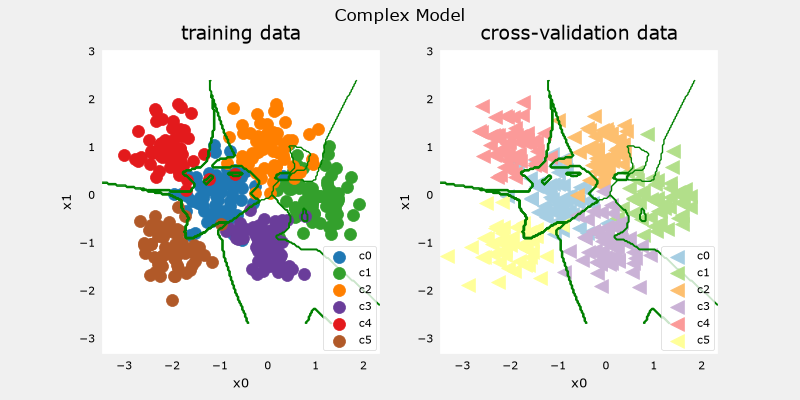

In [24]:
#make a model for plotting routines to call
model_predict = lambda Xl: np.argmax(tf.nn.softmax(model.predict(Xl)).numpy(),axis=1)
plt_nn(model_predict,X_train,y_train, classes, X_cv, y_cv, suptitle="Complex Model")

这个模型非常努力地捕捉每个类别的离群点。结果，它把一些交叉验证数据分错了类。让我们来计算分类误差。

In [25]:
training_cerr_complex = eval_cat_err(y_train, model_predict(X_train))
cv_cerr_complex = eval_cat_err(y_cv, model_predict(X_cv))
print(f"categorization error, training, complex model: {training_cerr_complex:0.3f}")
print(f"categorization error, cv,       complex model: {cv_cerr_complex:0.3f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
categorization error, training, complex model: 0.007
categorization error, cv,       complex model: 0.109


<a name="5.1"></a>
### 5.1 简单模型
现在，让我们尝试一个简单模型

<a name="ex04"></a>
### 练习 4

在下面，构建一个两层模型：
* 带 6 个单元的 Dense 层，relu 激活
* 带 6 个单元、线性激活的 Dense 层。
使用以下方式编译
* 用 `SparseCategoricalCrossentropy` 作为损失，记得使用 `from_logits=True`
* 学习率为 0.01 的 Adam 优化器。

In [26]:
# UNQ_C4
# GRADED CELL: model_s

tf.random.set_seed(1234)
model_s = Sequential(
    [
        ### START CODE HERE ###    
    Dense(units=6,activation='relu'),
    Dense(units=6,activation='linear')    
        
        ### END CODE HERE ### 
    ], name = "Simple"
)
model_s.compile(
    ### START CODE HERE ### 
    loss=SparseCategoricalCrossentropy(from_logits=True),
    optimizer=Adam(learning_rate=0.01),
    ### START CODE HERE ### 
)


In [27]:
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)

# BEGIN UNIT TEST
model_s.fit(
    X_train,y_train,
    epochs=1000
)
# END UNIT TEST

Epoch 1/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.5279  
Epoch 2/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.2735 
Epoch 3/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0432 
Epoch 4/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8593 
Epoch 5/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7228 
Epoch 6/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6206 
Epoch 7/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5439 
Epoch 8/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4862 
Epoch 9/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4423 
Epoch 10/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4078 
Epoch 11/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3801 
Epoch 12/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3570 
Epoch 13/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3354 
Epoch 14/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3108 
Epoch 15/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0

In [28]:
# BEGIN UNIT TEST
model_s.summary()

model_s_test(model_s, classes, X_train.shape[1])
# END UNIT TEST

Model: "Simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 6)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │            42 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 182 (1.42 KB)

 Trainable params: 60 (480.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 122 (976.00 B)

All tests passed!


<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
摘要应与此匹配（层的实例名可能会递增）
```
Model: "Simple"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
L1 (Dense)                   (None, 6)                 18        
_________________________________________________________________
L2 (Dense)                   (None, 6)                 42        
=================================================================
Total params: 60
Trainable params: 60
Non-trainable params: 0
_________________________________________________________________
```
  <details>
  <summary><font size="3" color="darkgreen"><b>点击获取更多提示</b></font></summary>
  
```python
tf.random.set_seed(1234)
model_s = Sequential(
    [
        Dense(6, activation = 'relu', name="L1"),            # @REPLACE
        Dense(classes, activation = 'linear', name="L2")     # @REPLACE
    ], name = "Simple"
)
model_s.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),     # @REPLACE
    optimizer=tf.keras.optimizers.Adam(0.01),     # @REPLACE
)

model_s.fit(
    X_train,y_train,
    epochs=1000
)                                   
``` 

1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 505us/step
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 506us/step


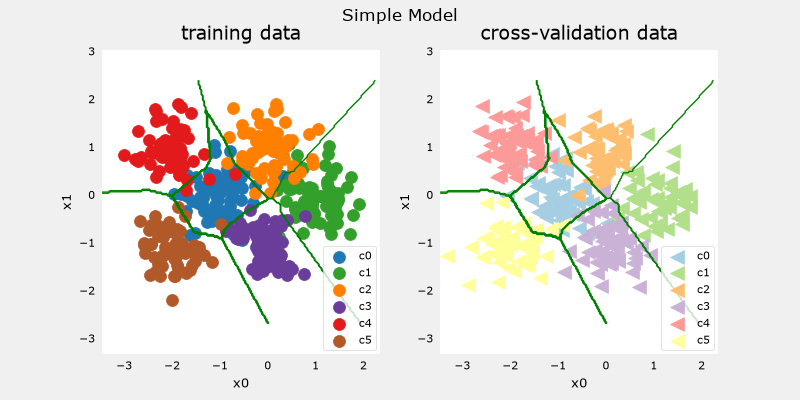

In [29]:
#make a model for plotting routines to call
model_predict_s = lambda Xl: np.argmax(tf.nn.softmax(model_s.predict(Xl)).numpy(),axis=1)
plt_nn(model_predict_s,X_train,y_train, classes, X_cv, y_cv, suptitle="Simple Model")

这个简单模型表现得相当不错。让我们来计算分类误差。

In [30]:
training_cerr_simple = eval_cat_err(y_train, model_predict_s(X_train))
cv_cerr_simple = eval_cat_err(y_cv, model_predict_s(X_cv))
print(f"categorization error, training, simple model, {training_cerr_simple:0.3f}, complex model: {training_cerr_complex:0.3f}" )
print(f"categorization error, cv,       simple model, {cv_cerr_simple:0.3f}, complex model: {cv_cerr_complex:0.3f}" )

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
categorization error, training, simple model, 0.068, complex model: 0.007
categorization error, cv,       simple model, 0.072, complex model: 0.109


我们的简单模型在训练数据上的分类误差略高，但在交叉验证数据上比更复杂的模型表现更好。

<a name="6"></a>
## 6 - 正则化
与多项式回归的情形一样，可以应用正则化来缓和一个更复杂模型的影响。让我们在下面试试这个。

<a name="ex05"></a>
### 练习 5

重建你的复杂模型，但这次包含正则化。
在下面，构建一个三层模型：
* 带 120 个单元的 Dense 层，relu 激活，`kernel_regularizer=tf.keras.regularizers.l2(0.1)`
* 带 40 个单元的 Dense 层，relu 激活，`kernel_regularizer=tf.keras.regularizers.l2(0.1)`
* 带 6 个单元、线性激活的 Dense 层。
使用以下方式编译
* 用 `SparseCategoricalCrossentropy` 作为损失，记得使用 `from_logits=True`
* 学习率为 0.01 的 Adam 优化器。

In [31]:
# UNQ_C5
# GRADED CELL: model_r

tf.random.set_seed(1234)
model_r = Sequential(
    [
        ### START CODE HERE ### 
    Dense(units=120,activation='relu',kernel_regularizer=tf.keras.regularizers.l2(0.1)),    
    Dense(units=40,activation='relu',kernel_regularizer=tf.keras.regularizers.l2(0.1)),
    Dense(units=6,activation='linear')    
        
        
        ### START CODE HERE ### 
    ], name= None
)
model_r.compile(
    ### START CODE HERE ### 
    loss=SparseCategoricalCrossentropy(from_logits=True),
    optimizer=Adam(learning_rate=0.01),
    ### START CODE HERE ### 
)


In [32]:
# BEGIN UNIT TEST
model_r.fit(
    X_train, y_train,
    epochs=1000
)
# END UNIT TEST

Epoch 1/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 4.4148  
Epoch 2/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.6920 
Epoch 3/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.3572 
Epoch 4/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1108 
Epoch 5/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0086 
Epoch 6/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9569 
Epoch 7/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9091 
Epoch 8/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8667 
Epoch 9/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8336 
Epoch 10/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8072 
Epoch 11/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7840 
Epoch 12/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7618 
Epoch 13/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7454 
Epoch 14/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7322 
Epoch 15/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0

In [33]:
# BEGIN UNIT TEST
model_r.summary()

model_r_test(model_r, classes, X_train.shape[1]) 
# END UNIT TEST

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 120)            │           360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 40)             │         4,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           246 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,340 (127.66 KB)

 Trainable params: 5,446 (42.55 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,894 (85.11 KB)

ddd
All tests passed!


<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
摘要应与此匹配（层的实例名可能会递增）
```
Model: "ComplexRegularized"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
L1 (Dense)                   (None, 120)               360       
_________________________________________________________________
L2 (Dense)                   (None, 40)                4840      
_________________________________________________________________
L3 (Dense)                   (None, 6)                 246       
=================================================================
Total params: 5,446
Trainable params: 5,446
Non-trainable params: 0
_________________________________________________________________
```
  <details>
  <summary><font size="3" color="darkgreen"><b>点击获取更多提示</b></font></summary>
  
```python
tf.random.set_seed(1234)
model_r = Sequential(
    [
        Dense(120, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(0.1), name="L1"), 
        Dense(40, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(0.1), name="L2"),  
        Dense(classes, activation = 'linear', name="L3")  
    ], name="ComplexRegularized"
)
model_r.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), 
    optimizer=tf.keras.optimizers.Adam(0.01),                             
)

model_r.fit(
    X_train,y_train,
    epochs=1000
)                                   
``` 

1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 550us/step
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 1s 551us/step


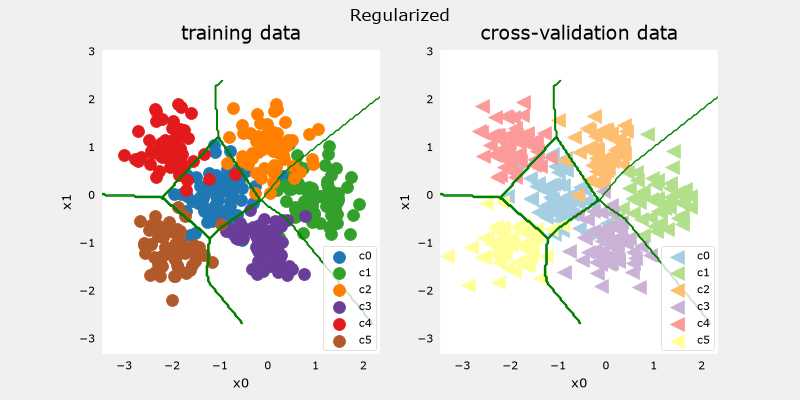

In [34]:
#make a model for plotting routines to call
model_predict_r = lambda Xl: np.argmax(tf.nn.softmax(model_r.predict(Xl)).numpy(),axis=1)
 
plt_nn(model_predict_r, X_train,y_train, classes, X_cv, y_cv, suptitle="Regularized")

这些结果看起来与"理想"模型非常相似。让我们来检查分类误差。

In [35]:
training_cerr_reg = eval_cat_err(y_train, model_predict_r(X_train))
cv_cerr_reg = eval_cat_err(y_cv, model_predict_r(X_cv))
test_cerr_reg = eval_cat_err(y_test, model_predict_r(X_test))
print(f"categorization error, training, regularized: {training_cerr_reg:0.3f}, simple model, {training_cerr_simple:0.3f}, complex model: {training_cerr_complex:0.3f}" )
print(f"categorization error, cv,       regularized: {cv_cerr_reg:0.3f}, simple model, {cv_cerr_simple:0.3f}, complex model: {cv_cerr_complex:0.3f}" )

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
categorization error, training, regularized: 0.072, simple model, 0.068, complex model: 0.007
categorization error, cv,       regularized: 0.066, simple model, 0.072, complex model: 0.109


简单模型在训练集上比正则化模型略好，但在交叉验证集上更差。

<a name="7"></a>
## 7 - 迭代以找到最优的正则化值
就像你在线性回归中所做的那样，你可以尝试许多正则化值。这段代码运行需要几分钟。如果你有时间，你可以运行它并检查结果。如果没有，你已经完成了本次作业中参与评分的部分！

In [36]:
tf.random.set_seed(1234)
lambdas = [0.0, 0.001, 0.01, 0.05, 0.1, 0.2, 0.3]
models=[None] * len(lambdas)

for i in range(len(lambdas)):
    lambda_ = lambdas[i]
    models[i] =  Sequential(
        [
            Dense(120, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(lambda_)),
            Dense(40, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(lambda_)),
            Dense(classes, activation = 'linear')
        ]
    )
    models[i].compile(
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=tf.keras.optimizers.Adam(0.01),
    )

    models[i].fit(
        X_train,y_train,
        epochs=1000
    )
    print(f"Finished lambda = {lambda_}")


Epoch 1/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.0582  
Epoch 2/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4097 
Epoch 3/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3481 
Epoch 4/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2731 
Epoch 5/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2420 
Epoch 6/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2428 
Epoch 7/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2348 
Epoch 8/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2235 
Epoch 9/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2193 
Epoch 10/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2187 
Epoch 11/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2161 
Epoch 12/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2156 
Epoch 13/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2115 
Epoch 14/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2087 
Epoch 15/1000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0

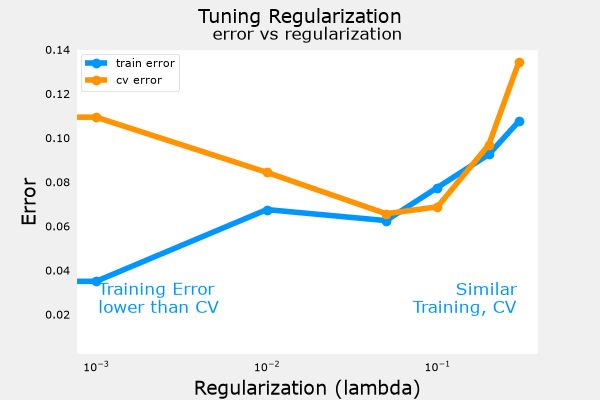

In [37]:
plot_iterate(lambdas, models, X_train, y_train, X_cv, y_cv)

随着正则化增大，模型在训练和交叉验证数据集上的性能收敛。对于这个数据集和模型，lambda > 0.01 似乎是一个合理的选择。

<a name="7.1"></a>
### 7.1 测试
让我们在测试集上试试我们优化过的模型，并把它们与"理想"性能作比较。

1050/1050 ━━━━━━━━━━━━━━━━━━━━ 0s 418us/step
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 0s 432us/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


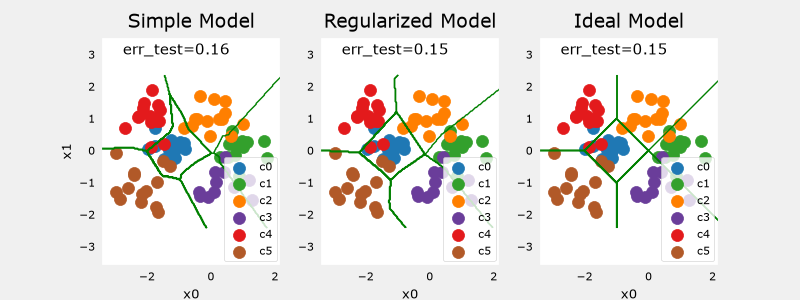

In [38]:
plt_compare(X_test,y_test, classes, model_predict_s, model_predict_r, centers)

我们的测试集很小，而且似乎有不少离群点，所以分类误差很高。然而，我们优化过的模型的性能与理想性能相当。

## 恭喜完成！
你已经熟悉了在评估你的机器学习模型时应使用的重要工具。即：
* 把数据划分成训练过的和未训练过的集合，让你能够区分欠拟合和过拟合
* 创建三个数据集——训练、交叉验证和测试——让你能够
    * 用训练集训练你的参数 $W,B$
    * 用交叉验证集调优模型参数，如复杂度、正则化和样本数量
    * 用测试集评估你的"真实世界"性能。
* 比较训练与交叉验证的性能，可以洞察一个模型倾向于过拟合（高方差）还是欠拟合（高偏差）

<details>
  <summary><font size="2" color="darkgreen"><b>如果你想试验任何不参与评分的代码，请点击这里。</b></font></summary>
    <p><i><b>重要提示：请仅在你已经通过本次作业之后再这样做，以避免自动评分器出现问题。</b></i>
    <ol>
        <li> 在笔记本的菜单上，点击 "View" > "Cell Toolbar" > "Edit Metadata"</li>
        <li> 点击你想锁定/解锁的代码单元格旁边的 "Edit Metadata" 按钮</li>
        <li> 把 "editable" 的属性值设为：
            <ul>
                <li> 如果你想解锁它，设为 "true" </li>
                <li> 如果你想锁定它，设为 "false" </li>
            </ul>
        </li>
        <li> 在笔记本的菜单上，点击 "View" > "Cell Toolbar" > "None" </li>
    </ol>
    <p> 这里有一个简短的演示，展示如何执行上述步骤：
        <br>
        <img src="https://drive.google.com/uc?export=view&id=14Xy_Mb17CZVgzVAgq7NCjMVBvSae3xO1" align="center" alt="unlock_cells.gif">
</details>